# 空间分布、站点潮汐失衡与车辆调度优化

**负责人：康炜奕**  
协作成员：马文博（数据清洗与基础探索）、陈宇涵（时间规律与需求预测）

本 Notebook 使用成员 A 导出的 **站点有效集 180,914 条** 记录，完成热门站点与高频 OD 走廊统计、站点热度空间分布、早晚高峰净流量与失衡指数计算，以及基于最近邻匹配的调运方案测算，对应报告中的图9–图12。

运行前请安装项目 `requirements.txt` 中的依赖，并在 Jupyter 中选择 **Python (Pyclass)** 内核，然后执行“重启内核并运行全部单元格”。可从项目根目录或 `notebooks/` 目录启动。

运行会重新生成图9–图12 的 300 DPI PNG、自包含 HTML 和配套统计表；原始 CSV 与清洗结果保持不变，全部筛选口径直接复用 `src/` 中的现有代码，不在此重新定义。

## 1. 研究问题与分析思路

本部分回答四个问题：

1. 骑行需求在站点上如何集中，哪些走廊承担了主要的站点间联系？
2. 站点在空间上呈现怎样的热度与流入流出方向？
3. 早晚高峰的净流量与失衡指数有多大，哪些站点最需要调度？
4. 如何在最近邻约束下把积车点的车辆调到缺车点，形成可执行的调运方案？

分析流程为“站点与 OD 汇总 → 热度空间分布 → 早晚高峰净流量与失衡指数 → 最近邻调运匹配”。站点、OD、失衡与调运四部分共用同一份站点有效集，分母与口径在下方统一列出。

In [1]:
from pathlib import Path
import os
import sys

current = Path.cwd().resolve()
ROOT = next(
    (path for path in (current, *current.parents)
     if (path / "src/spatial_analysis.py").is_file()
     and (path / "config/cleaning_rules.json").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("请在 Pyclass 项目根目录或 notebooks 目录启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "tmp/matplotlib"))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as DisplayImage, Markdown, display

from src.imbalance_dispatch import (
    build_dispatch_plan, build_hourly_panel, build_peak_imbalance,
    choose_representatives, peak_profile, plot_peak_divergence, plot_tidal_curves,
    weekday_count,
)
from src.spatial_analysis import (
    build_od_corridors, build_station_summary, corridor_concentration,
    load_station_trips, plot_station_heatmap, plot_top_stations_od,
)
from src.utils import FIGURE_DIR, PROCESSED_DIR, TABLE_DIR, save_figure, set_plot_style

FONT = set_plot_style()
print("中文字体：", FONT)

中文字体： Microsoft YaHei


## 2. 数据接口与统计口径

样本为成员 A 导出的 `data/processed/station_trips.csv`，即双端站点 ID 完整、时长 1–180 分钟的 180,914 条记录。章节一已说明该子集占全量有效集的 77.59%，其余 52,266 条因缺站点不参与站点级分析。

净流量与失衡指数定义如下（$t$ 为统计时段）：

```math
F_{i,t} = D_{i,t} - A_{i,t}, \qquad I_{i,t} = \frac{\left|F_{i,t}\right|}{D_{i,t} + A_{i,t} + 1}
```

其中 $D_{i,t}$、$A_{i,t}$ 分别为站点 $i$ 在时段 $t$ 的出发量与到达量。$F>0$ 表示净流出（站点缺车），$F<0$ 表示净流入（站点积车）；分母加 1 是防零平滑项，避免低流量站点在 $D+A=0$ 时出现无定义的比值。

In [2]:
station = load_station_trips()
summary = build_station_summary(station)
corridors = build_od_corridors(station)
days = weekday_count(station)

display(pd.DataFrame([
    {"项目": "站点有效集记录数", "数值": f"{len(station):,}"},
    {"项目": "出现过的站点数", "数值": len(summary)},
    {"项目": "非环线骑行次数", "数值": f"{int(corridors.total_trips.sum()):,}"},
    {"项目": "非环线 OD 站点对", "数值": f"{len(corridors):,}"},
    {"项目": "环线骑行次数", "数值": f"{int(station.start_station_id.eq(station.end_station_id).sum()):,}"},
    {"项目": "统计口径内工作日天数", "数值": days},
]))

assert len(station) == 180914, "站点有效集行数应与章节一导出的站点子集一致。"
assert int(summary.departures.sum()) == len(station) == int(summary.arrivals.sum())

,项目,数值
0,站点有效集记录数,"180,914"
1,出现过的站点数,760
2,非环线骑行次数,"176,303"
3,非环线 OD 站点对,"29,005"
4,环线骑行次数,"4,611"
5,统计口径内工作日天数,23


In [3]:
caliber = pd.DataFrame([
    ("样本", "站点有效集：双端站点 ID 完整、1 ≤ 时长 ≤ 180 分钟"),
    ("工作日", "周一至周五，含 1/1 与 1/15；与章节一的 is_weekend 定义一致"),
    ("早高峰", "7:00–9:59，共 3 个小时"),
    ("晚高峰", "17:00–19:59，共 3 个小时"),
    ("到达量归属", "按还车时间 ended_at 归入对应小时，而不是沿用出发小时"),
    ("净流量 F", "F = 出发量 − 到达量；F > 0 缺车，F < 0 积车"),
    ("失衡指数 I", "I = |F| ÷ (出发量 + 到达量 + 1)，分母加 1 为防零平滑项"),
    ("分级", "严重：|F| ≥ 60 且 I ≥ 0.30；中度：|F| ≥ 30 且 I ≥ 0.20；轻度：|F| ≥ 10"),
    ("调运匹配", "早/晚高峰分别匹配，最近邻优先，单程不超过 6 km，量纲为辆/日"),
], columns=["项目", "本部分口径"])
display(caliber)

,项目,本部分口径
0,样本,站点有效集：双端站点 ID 完整、1 ≤ 时长 ≤ 180 分钟
1,工作日,周一至周五，含 1/1 与 1/15；与章节一的 is_weekend 定义一致
2,早高峰,7:00–9:59，共 3 个小时
3,晚高峰,17:00–19:59，共 3 个小时
4,到达量归属,按还车时间 ended_at 归入对应小时，而不是沿用出发小时
5,净流量 F,F = 出发量 − 到达量；F > 0 缺车，F < 0 积车
6,失衡指数 I,I = |F| ÷ (出发量 + 到达量 + 1)，分母加 1 为防零平滑项
7,分级,严重：|F| ≥ 60 且 I ≥ 0.30；中度：|F| ≥ 30 且 I ≥ 0.20；...
8,调运匹配,早/晚高峰分别匹配，最近邻优先，单程不超过 6 km，量纲为辆/日


## 3. 站点总流量与高频 OD 走廊

站点总流量按出发量与到达量合计排序。OD 走廊把 $A \to B$ 与 $B \to A$ 合并为一条无向走廊，同时保留两个方向各自的次数，以避免把早晚潮汐的两个方向误当作两条独立走廊；环线（起终点相同）不计入走廊。

In [4]:
top10 = summary.head(10)[["station_name", "departures", "arrivals", "total_trips", "net_flow", "imbalance_index"]]
display(top10.rename(columns={
    "station_name": "站点", "departures": "出发量", "arrivals": "到达量",
    "total_trips": "总流量", "net_flow": "净流量", "imbalance_index": "失衡指数",
}).round({"失衡指数": 3}))
display(Markdown(
    f"总流量最高的是 **{summary.station_name.iloc[0]}**（{int(summary.total_trips.iloc[0]):,} 次）；"
    f"Top10 站点合计 **{int(summary.total_trips.head(10).sum()):,}** 次，占站点总流量的 "
    f"**{summary.total_trips.head(10).sum() / summary.total_trips.sum():.2%}**。"
    f"净流量绝对值最大的是 **{summary.loc[summary.net_flow.abs().idxmax(), 'station_name']}**。"
))

,站点,出发量,到达量,总流量,净流量,失衡指数
0,Columbus Circle / Union Station,2845,2786,5631,59,0.010
1,New Hampshire Ave & T St NW,2340,2327,4667,13,0.003
2,15th & P St NW,1921,1908,3829,13,0.003
3,14th & V St NW,1749,1754,3503,-5,0.001
4,Eastern Market Metro / Pennsylvania Ave & 8th ...,1708,1743,3451,-35,0.010
5,5th & K St NW,1718,1728,3446,-10,0.003
6,M St & Delaware Ave NE,1596,1594,3190,2,0.001
7,1st & M St NE,1567,1582,3149,-15,0.005
8,Massachusetts Ave & Dupont Circle NW,1491,1603,3094,-112,0.036
9,8th & O St NW,1448,1437,2885,11,0.004


总流量最高的是 **Columbus Circle / Union Station**（5,631 次）；Top10 站点合计 **36,845** 次，占站点总流量的 **10.18%**。净流量绝对值最大的是 **Adams Mill & Columbia Rd NW**。

In [5]:
concentration = corridor_concentration(corridors)
display(corridors.head(10)[["name_a", "name_b", "trips_a_to_b", "trips_b_to_a", "total_trips", "dominant_share"]]
        .rename(columns={"name_a": "站点 A", "name_b": "站点 B", "trips_a_to_b": "A→B",
                         "trips_b_to_a": "B→A", "total_trips": "合计", "dominant_share": "主向占比"})
        .round({"主向占比": 3}))
display(Markdown(
    f"非环线骑行 **{concentration['non_loop_trips']:,}** 次，分布在 **{len(corridors):,}** 个站点对上；"
    f"其中 **{concentration['station_pairs_both_directions']:,}** 个站点对存在双向骑行。"
    f"Top1 / Top10 / Top50 走廊分别占非环线骑行的 "
    f"**{concentration['top1_share']:.2%}** / **{concentration['top10_share']:.2%}** / "
    f"**{concentration['top50_share']:.2%}**，站点间的骑行联系高度分散。"
))

,站点 A,站点 B,A→B,B→A,合计,主向占比
0,Columbus Circle / Union Station,8th & F St NE,243,210,453,0.536
1,6th & H St NE,Columbus Circle / Union Station,140,194,334,0.581
2,Columbus Circle / Union Station,Maryland Ave & E St NE,149,152,301,0.505
3,Eastern Market Metro / Pennsylvania Ave & 8th ...,Lincoln Park / 13th & East Capitol St NE,153,112,265,0.577
4,New Hampshire Ave & T St NW,18th & New Hampshire Ave NW,104,110,214,0.514
5,1st & M St NE,New Jersey Ave & F St NW,119,94,213,0.559
6,15th & P St NW,New Hampshire Ave & T St NW,109,97,206,0.529
7,Eastern Market Metro / Pennsylvania Ave & 8th ...,3rd & G St SE,64,116,180,0.644
8,Columbus Circle / Union Station,10th & H St NE,103,71,174,0.592
9,New Hampshire & Gallatin St NW,Fort Totten Metro,92,71,163,0.564


非环线骑行 **176,303** 次，分布在 **29,005** 个站点对上；其中 **14,515** 个站点对存在双向骑行。Top1 / Top10 / Top50 走廊分别占非环线骑行的 **0.26%** / **1.42%** / **4.22%**，站点间的骑行联系高度分散。

## 4. 图9：Top15 热门站点与高频 OD 走廊

左图比较总流量前 15 个站点的出发量与到达量，条尾数字为净流量；右图给出双向合并后的高频走廊，标签方向为该走廊的主向。

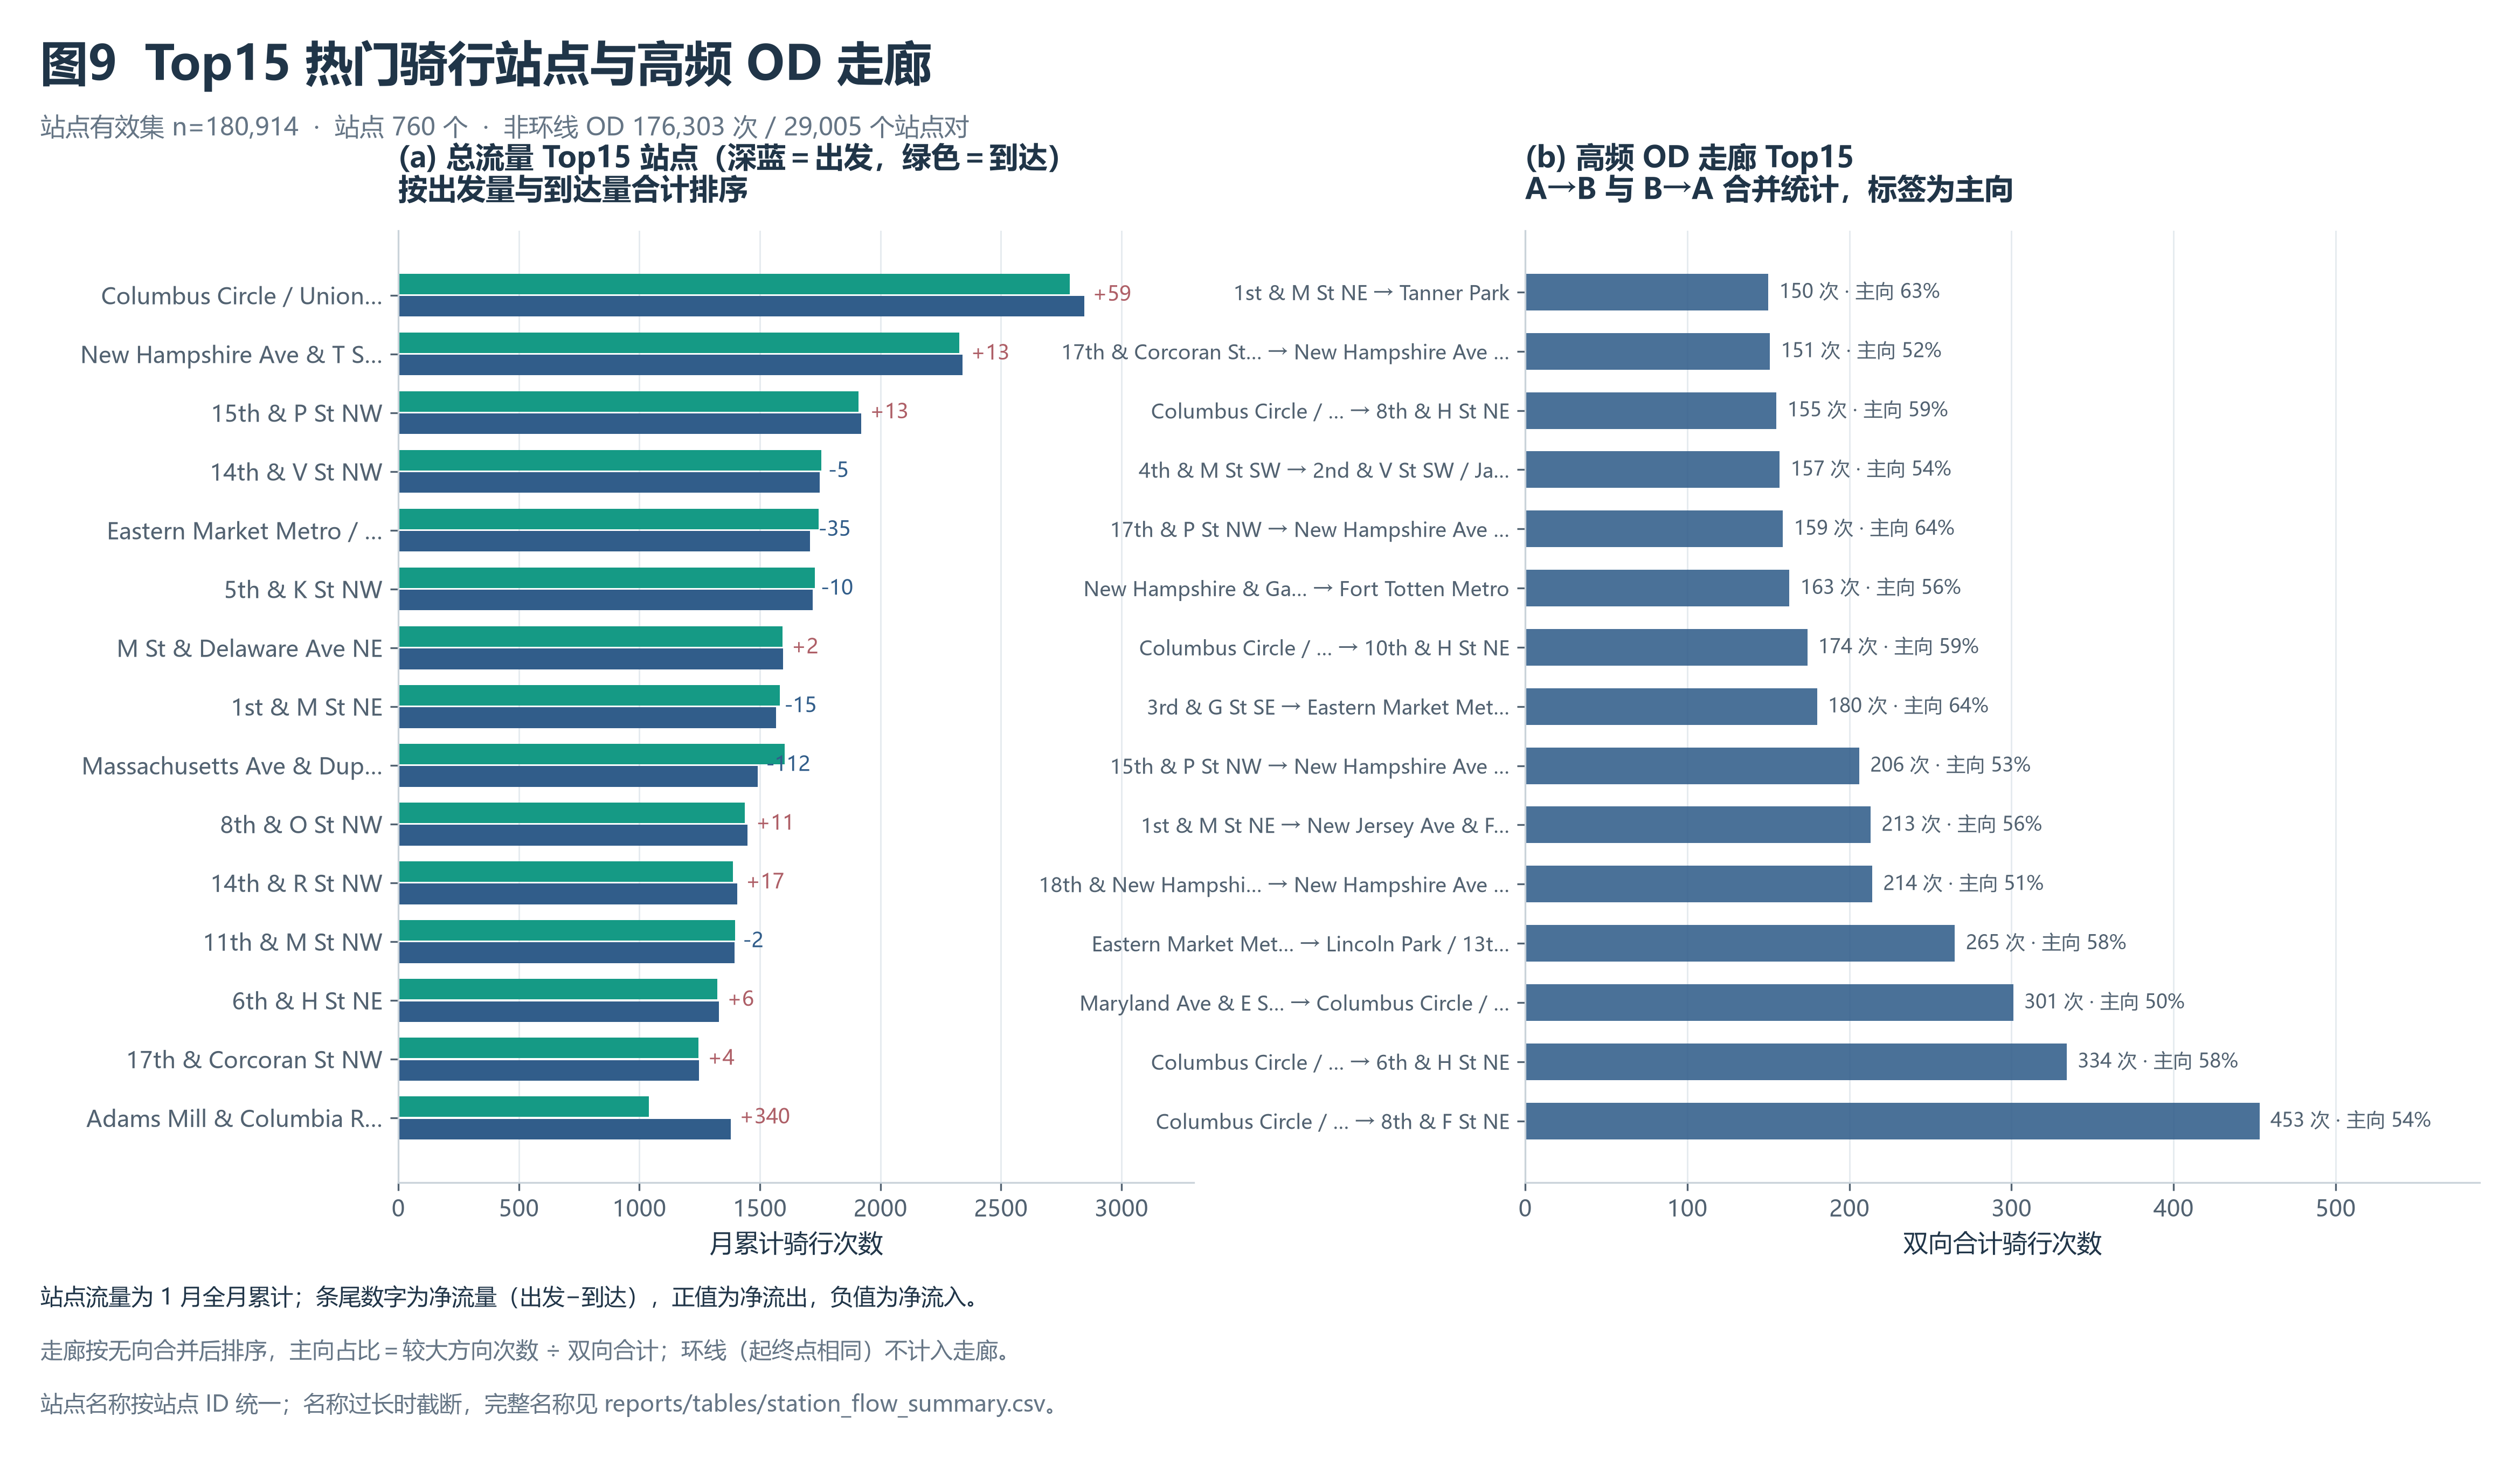

In [6]:
figure = plot_top_stations_od(summary, corridors, station)
fig09 = save_figure(figure, "fig09_top_stations_od.png")
plt.close(figure)
display(DisplayImage(filename=str(fig09), width=1150))

## 5. 图10：站点骑行热度空间分布

气泡面积表示站点月总流量，颜色表示月净流量方向（红＝净流出，蓝＝净流入）。主城取景窗口外另有 168 个外围站点，合计仅占骑行量 1.25%，为突出主城结构未绘出，但仍计入全部统计。

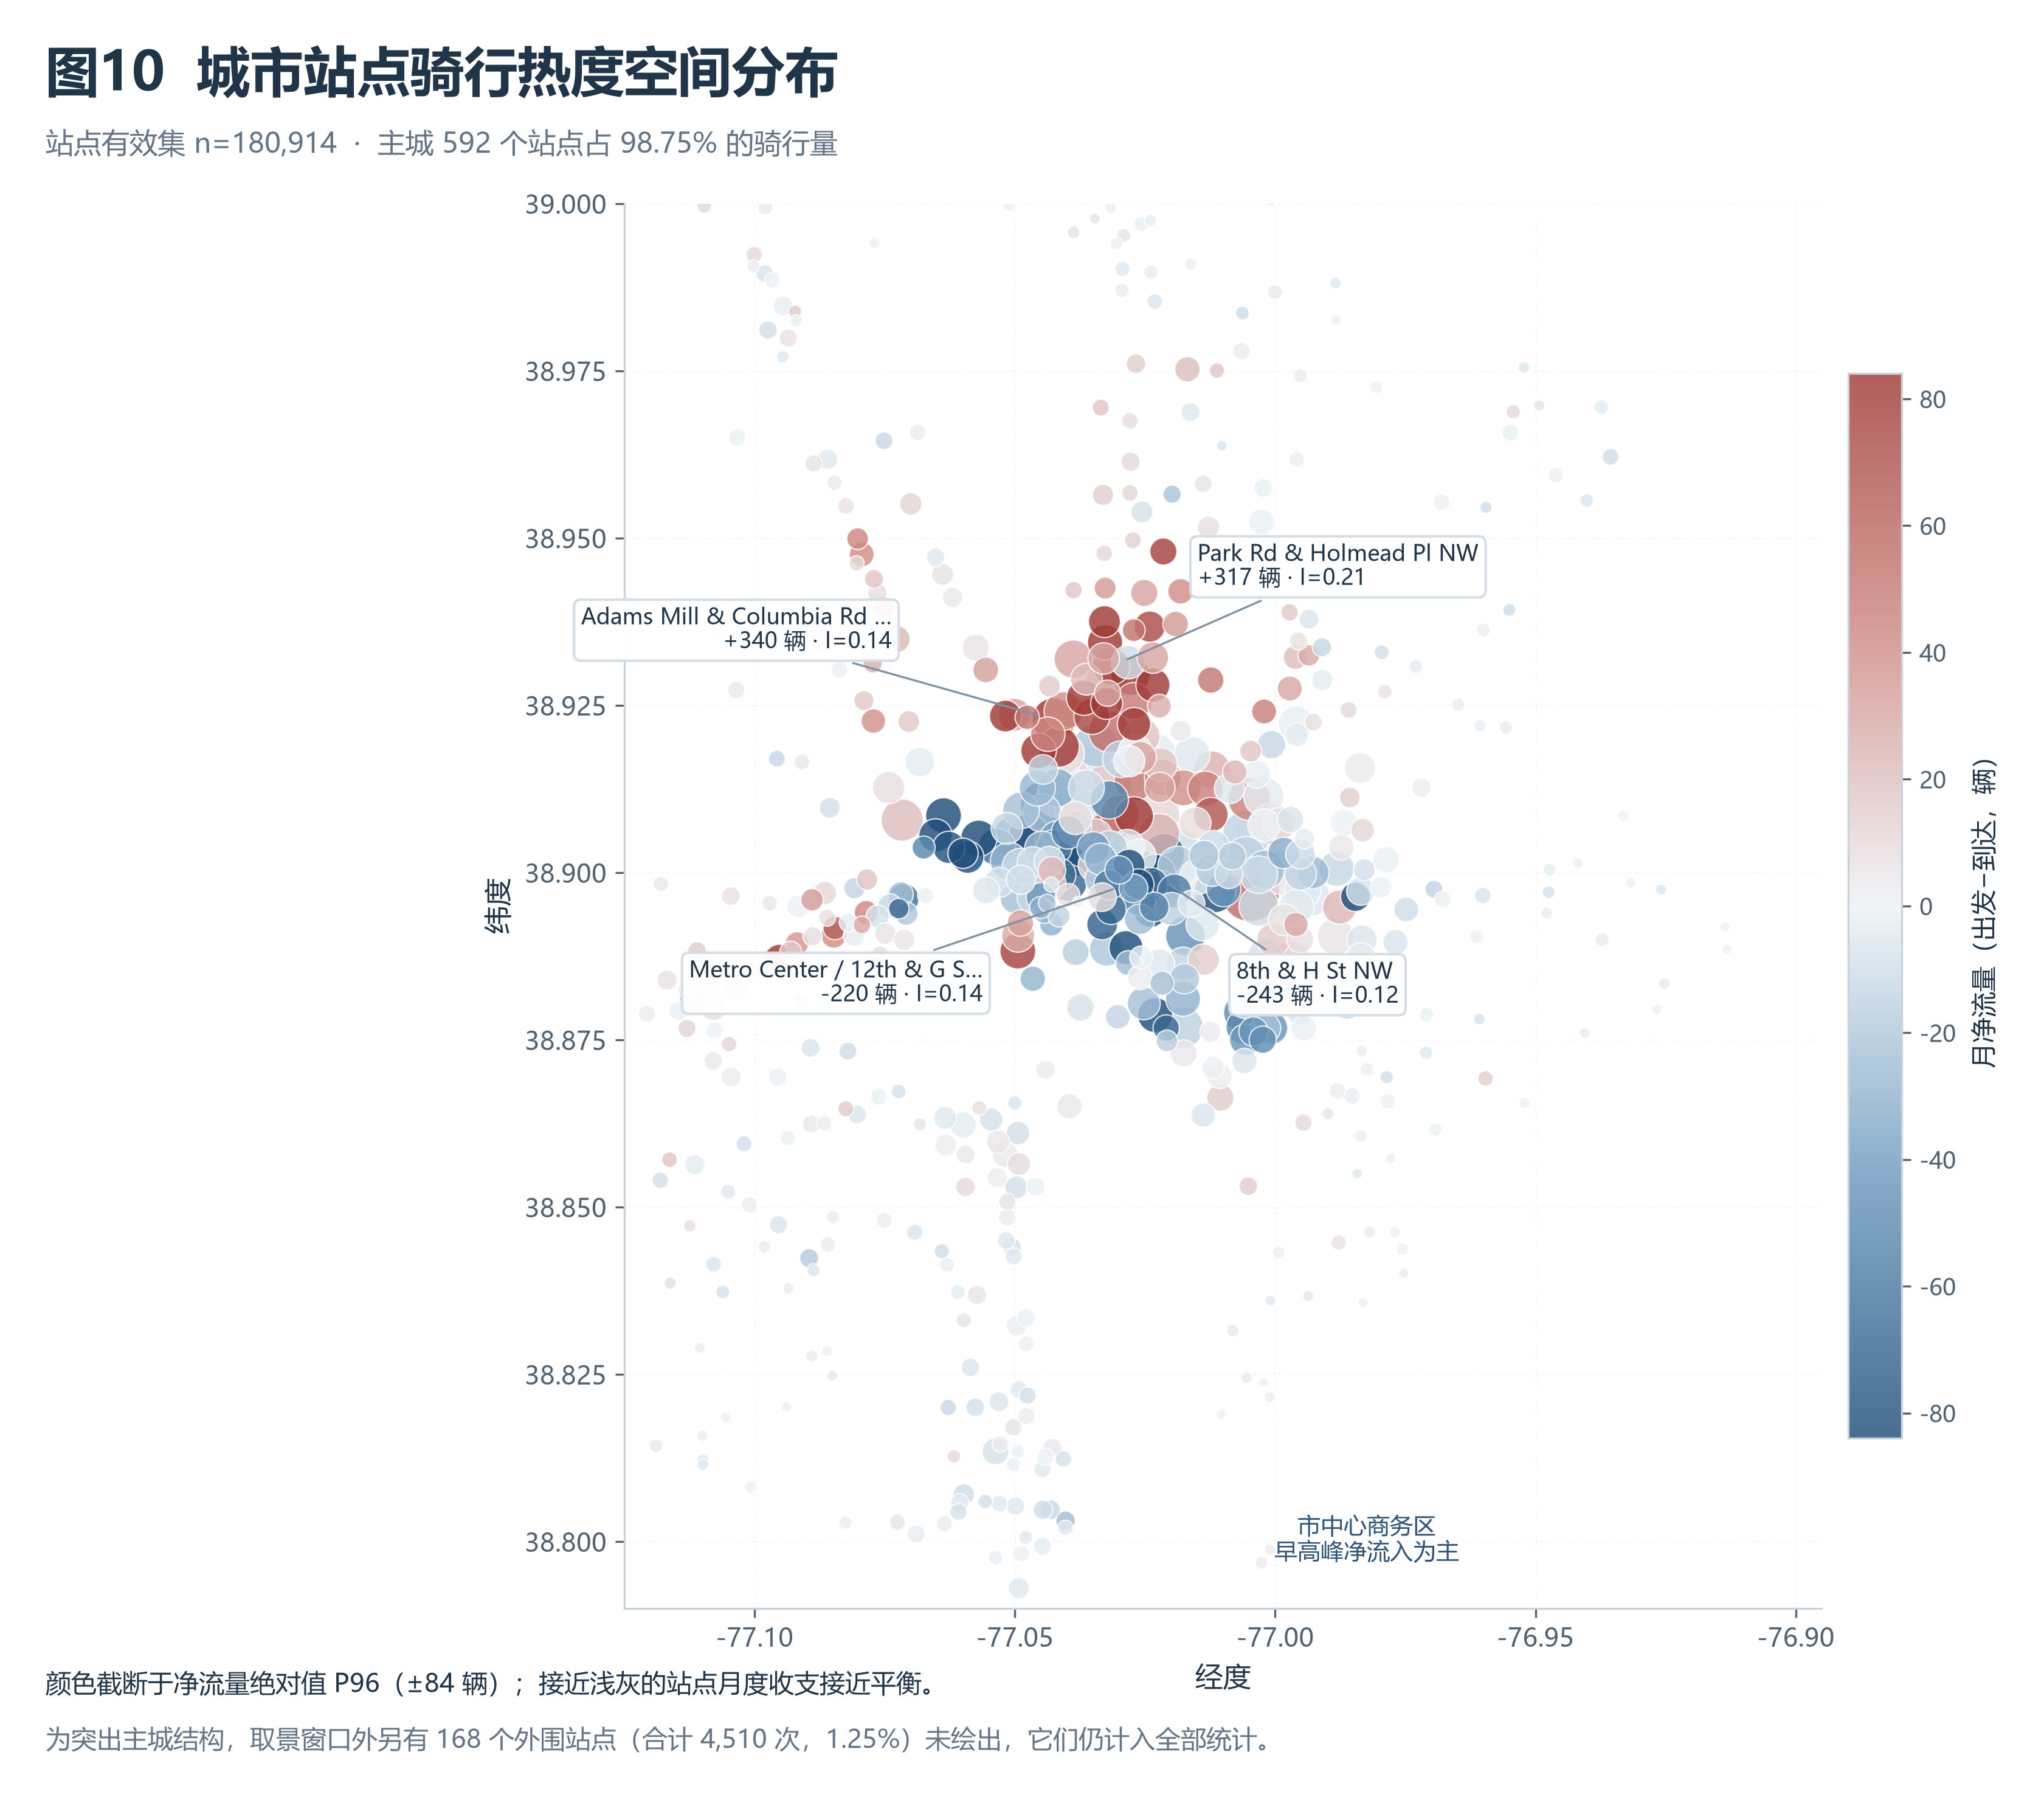

In [7]:
figure = plot_station_heatmap(summary, station)
fig10 = save_figure(figure, "fig10_station_heatmap.png")
plt.close(figure)
display(DisplayImage(filename=str(fig10), width=900))

## 6. 早晚高峰净流量与失衡指数

按早、晚高峰分别汇总每个站点的出发量、到达量、净流量与失衡指数，并按阈值分级。月净流量在早晚高峰之间大多相互抵消，因此图10 的颜色普遍较浅；真正的失衡要看分时段的结果。

In [8]:
peak = build_peak_imbalance(station)
panel = build_hourly_panel(station)
am = peak.loc[peak.period.eq("早高峰")]
pm = peak.loc[peak.period.eq("晚高峰")]

counts = (pd.crosstab(peak.period, peak.grade)
          .reindex(columns=["严重失衡", "中度失衡", "轻度失衡", "基本均衡"], fill_value=0))
display(counts)
display(am.nlargest(5, "net_flow")[["station_name", "departures", "arrivals", "net_flow", "imbalance_index", "grade"]]
        .rename(columns={"station_name": "站点", "departures": "出发量", "arrivals": "到达量",
                         "net_flow": "净流量", "imbalance_index": "失衡指数", "grade": "分级"})
        .round({"失衡指数": 3}))
display(Markdown(
    f"早高峰 **{int(am.departures.sum()):,}** 次、晚高峰 **{int(pm.departures.sum()):,}** 次骑行。"
    f"早高峰缺车合计 **{int(am.loc[am.net_flow.gt(0), 'net_flow'].sum()):,}** 辆、"
    f"严重失衡 **{int(am.grade.eq('严重失衡').sum())}** 个站点。"
))

grade,严重失衡,中度失衡,轻度失衡,基本均衡
period,,,,
早高峰,156,66,144,308
晚高峰,44,73,197,385


,站点,出发量,到达量,净流量,失衡指数,分级
0,New Hampshire Ave & T St NW,417,153,264,0.462,严重失衡
1,14th & V St NW,368,105,263,0.555,严重失衡
2,17th & Corcoran St NW,269,53,216,0.669,严重失衡
3,8th & F St NE,250,47,203,0.681,严重失衡
4,15th & W St NW,255,59,196,0.622,严重失衡


早高峰 **28,779** 次、晚高峰 **37,690** 次骑行。早高峰缺车合计 **13,628** 辆、严重失衡 **156** 个站点。

## 7. 图11：早晚高峰净流量正负双向对比

每个面板上方为积车站点（净流入，向左），下方为缺车站点（净流出，向右）；括号内为失衡指数。同一批站点在早晚高峰方向相反，构成潮汐往复。

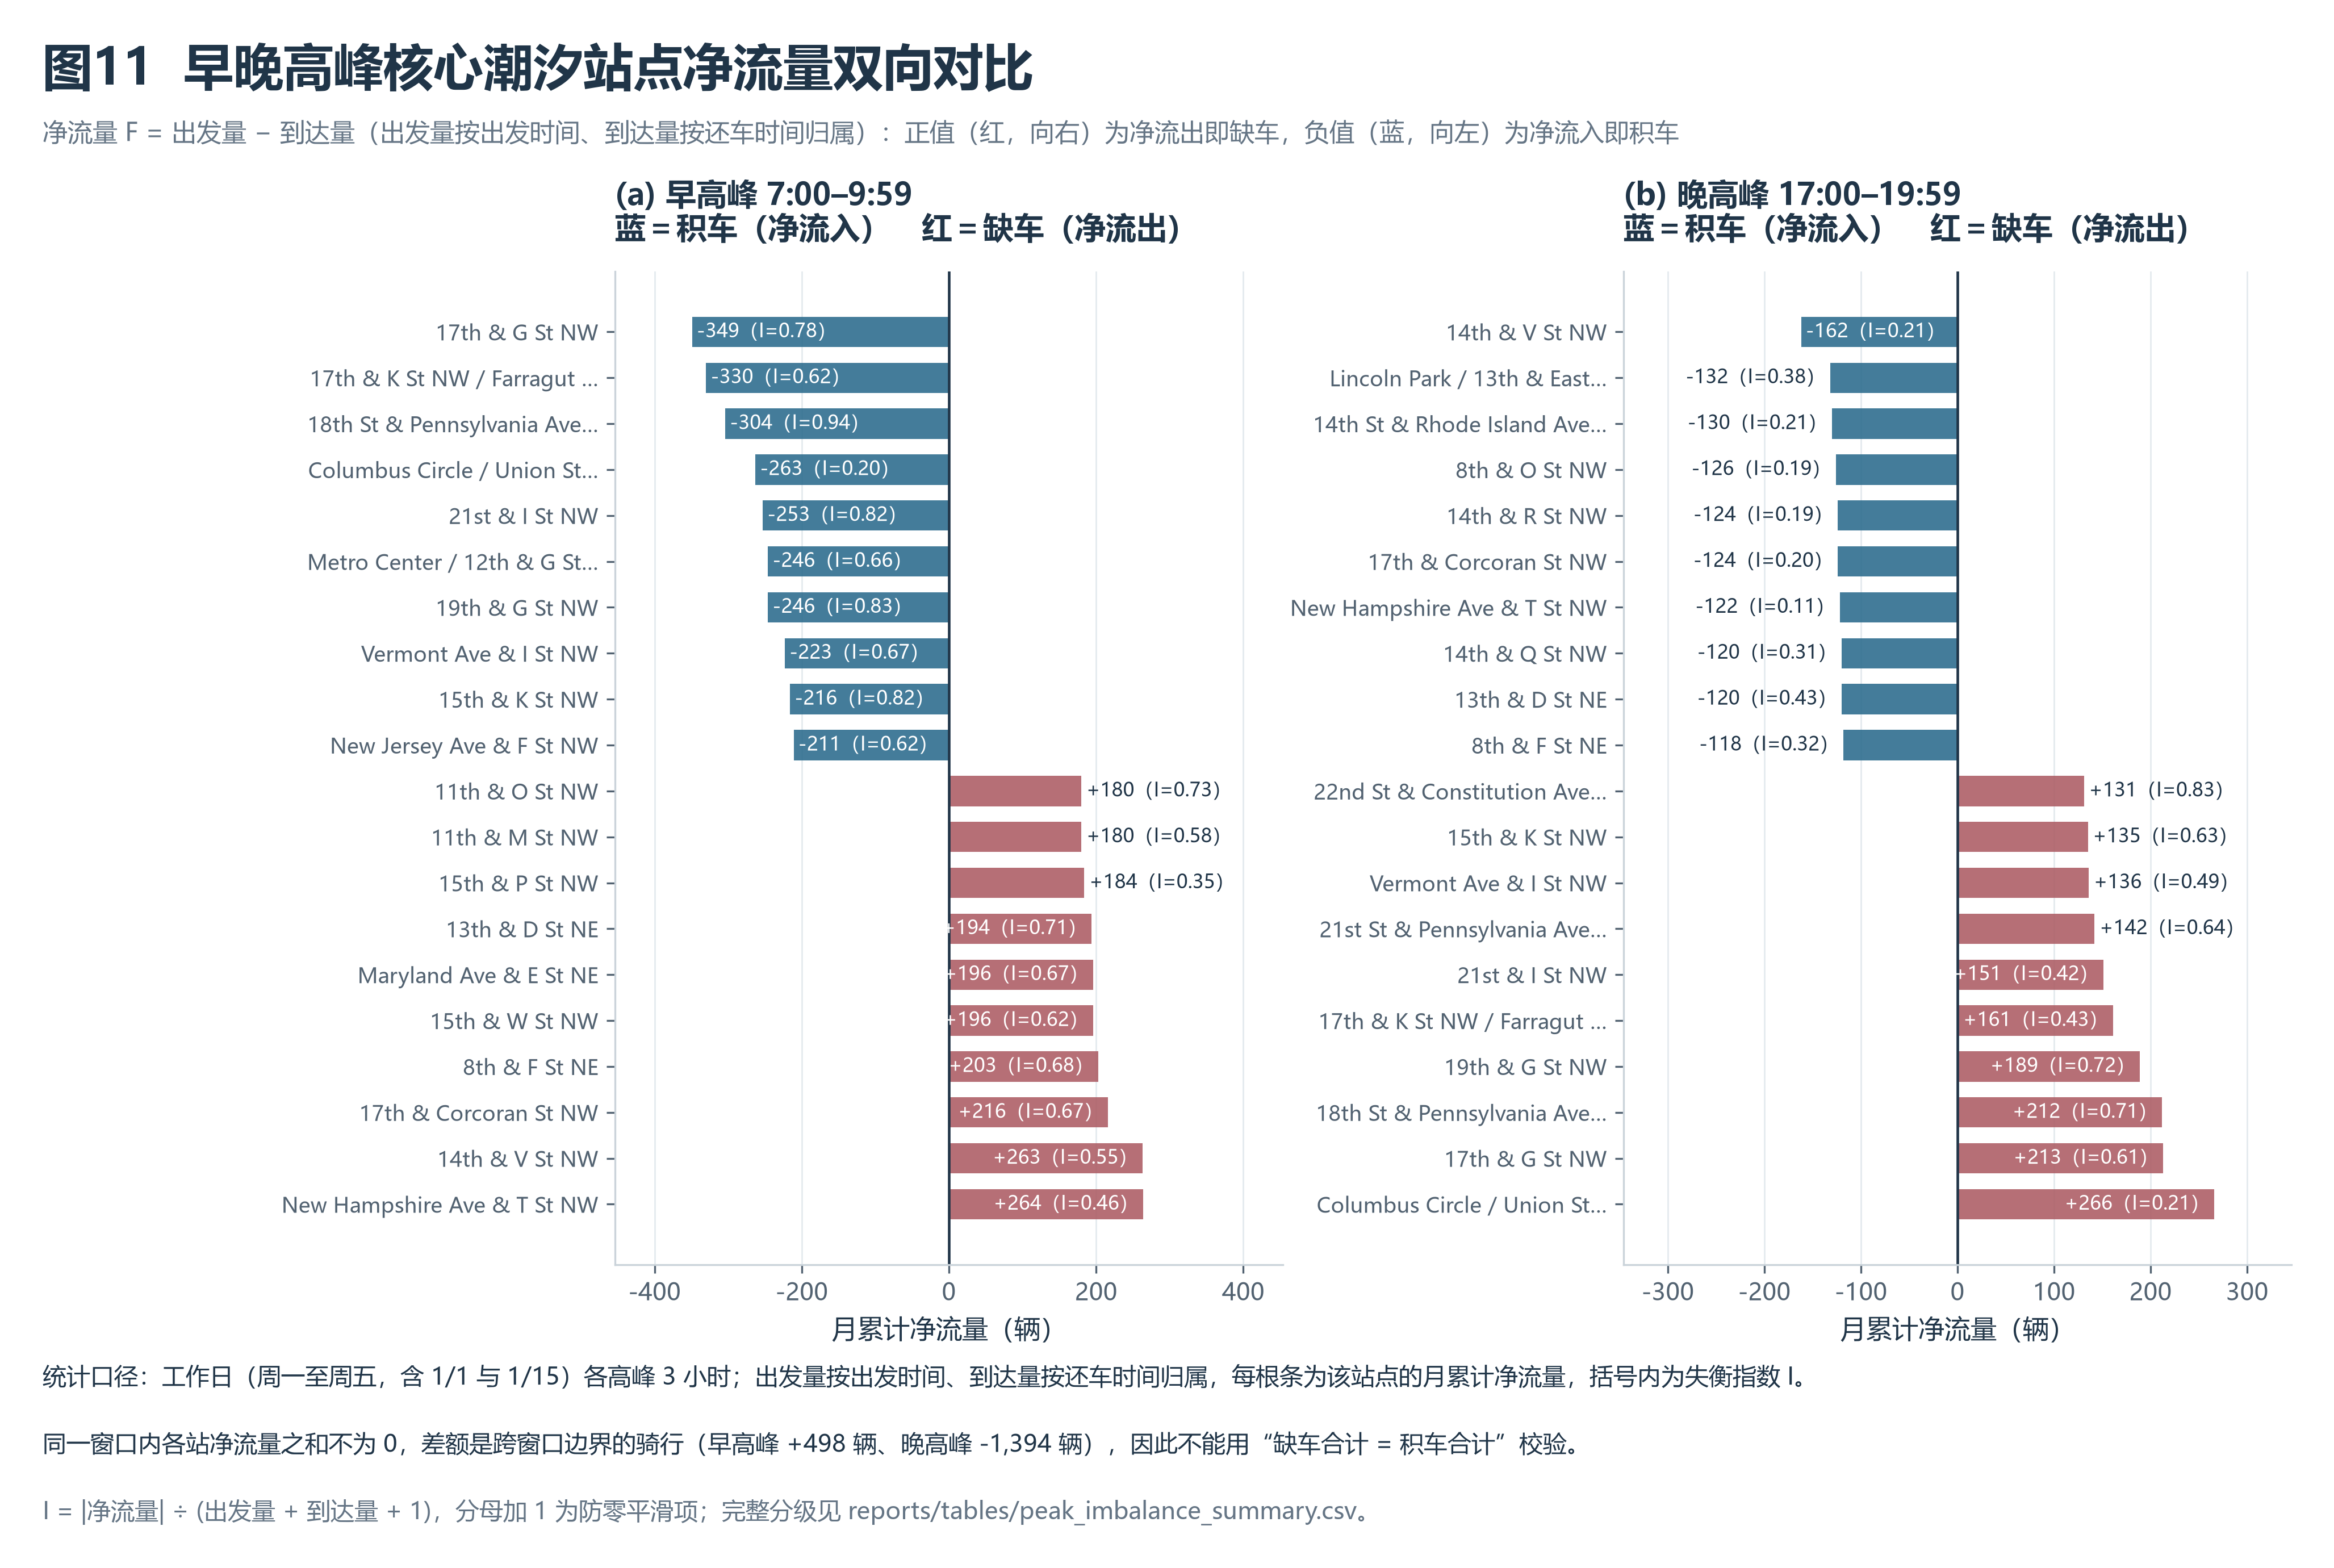

In [9]:
figure = plot_peak_divergence(peak)
fig11 = save_figure(figure, "fig11_peak_divergence.png")
plt.close(figure)
display(DisplayImage(filename=str(fig11), width=1220))

## 8. 图12：居住区与商务区站点的 24 小时潮汐曲线

代表站点按“早高峰净流出最大（居住区）”与“早高峰净流入最大（商务区）”自动选取，且要求月流量不低于 800 次，避免选到样本过小的站点。

In [10]:
representatives = choose_representatives(peak, summary)
rows = []
for label, name in representatives:
    record = am.loc[am.station_name.eq(name)].iloc[0]
    rows.append({"角色": label, "站点": name, "早高峰出发": int(record.departures),
                 "早高峰到达": int(record.arrivals), "净流量 F": int(record.net_flow),
                 "失衡指数 I": round(float(record.imbalance_index), 3)})
display(pd.DataFrame(rows))

profiles = {label: peak_profile(station, name) for label, name in representatives}
display(pd.concat([profiles["居住区"].iloc[[7, 8, 9, 17, 18, 19, 23]],
                   profiles["商务区"].iloc[[7, 8, 9, 17, 18, 19, 23]]])
        .loc[:, ["station_name", "hour", "departures", "arrivals", "net_flow", "cumulative_net"]]
        .rename(columns={"station_name": "站点", "hour": "小时", "departures": "出发量",
                         "arrivals": "到达量", "net_flow": "净流量", "cumulative_net": "累计净流量"}))

,角色,站点,早高峰出发,早高峰到达,净流量 F,失衡指数 I
0,居住区,New Hampshire Ave & T St NW,417,153,264,0.462
1,商务区,17th & G St NW,50,399,-349,0.776


,站点,小时,出发量,到达量,净流量,累计净流量
7,New Hampshire Ave & T St NW,7,224,48,176,167
8,New Hampshire Ave & T St NW,8,142,56,86,253
9,New Hampshire Ave & T St NW,9,51,49,2,255
17,New Hampshire Ave & T St NW,17,152,267,-115,-19
18,New Hampshire Ave & T St NW,18,178,199,-21,-40
19,New Hampshire Ave & T St NW,19,147,133,14,-26
23,New Hampshire Ave & T St NW,23,48,35,13,-6
7,17th & G St NW,7,18,27,-9,-21
8,17th & G St NW,8,14,227,-213,-234
9,17th & G St NW,9,18,145,-127,-361


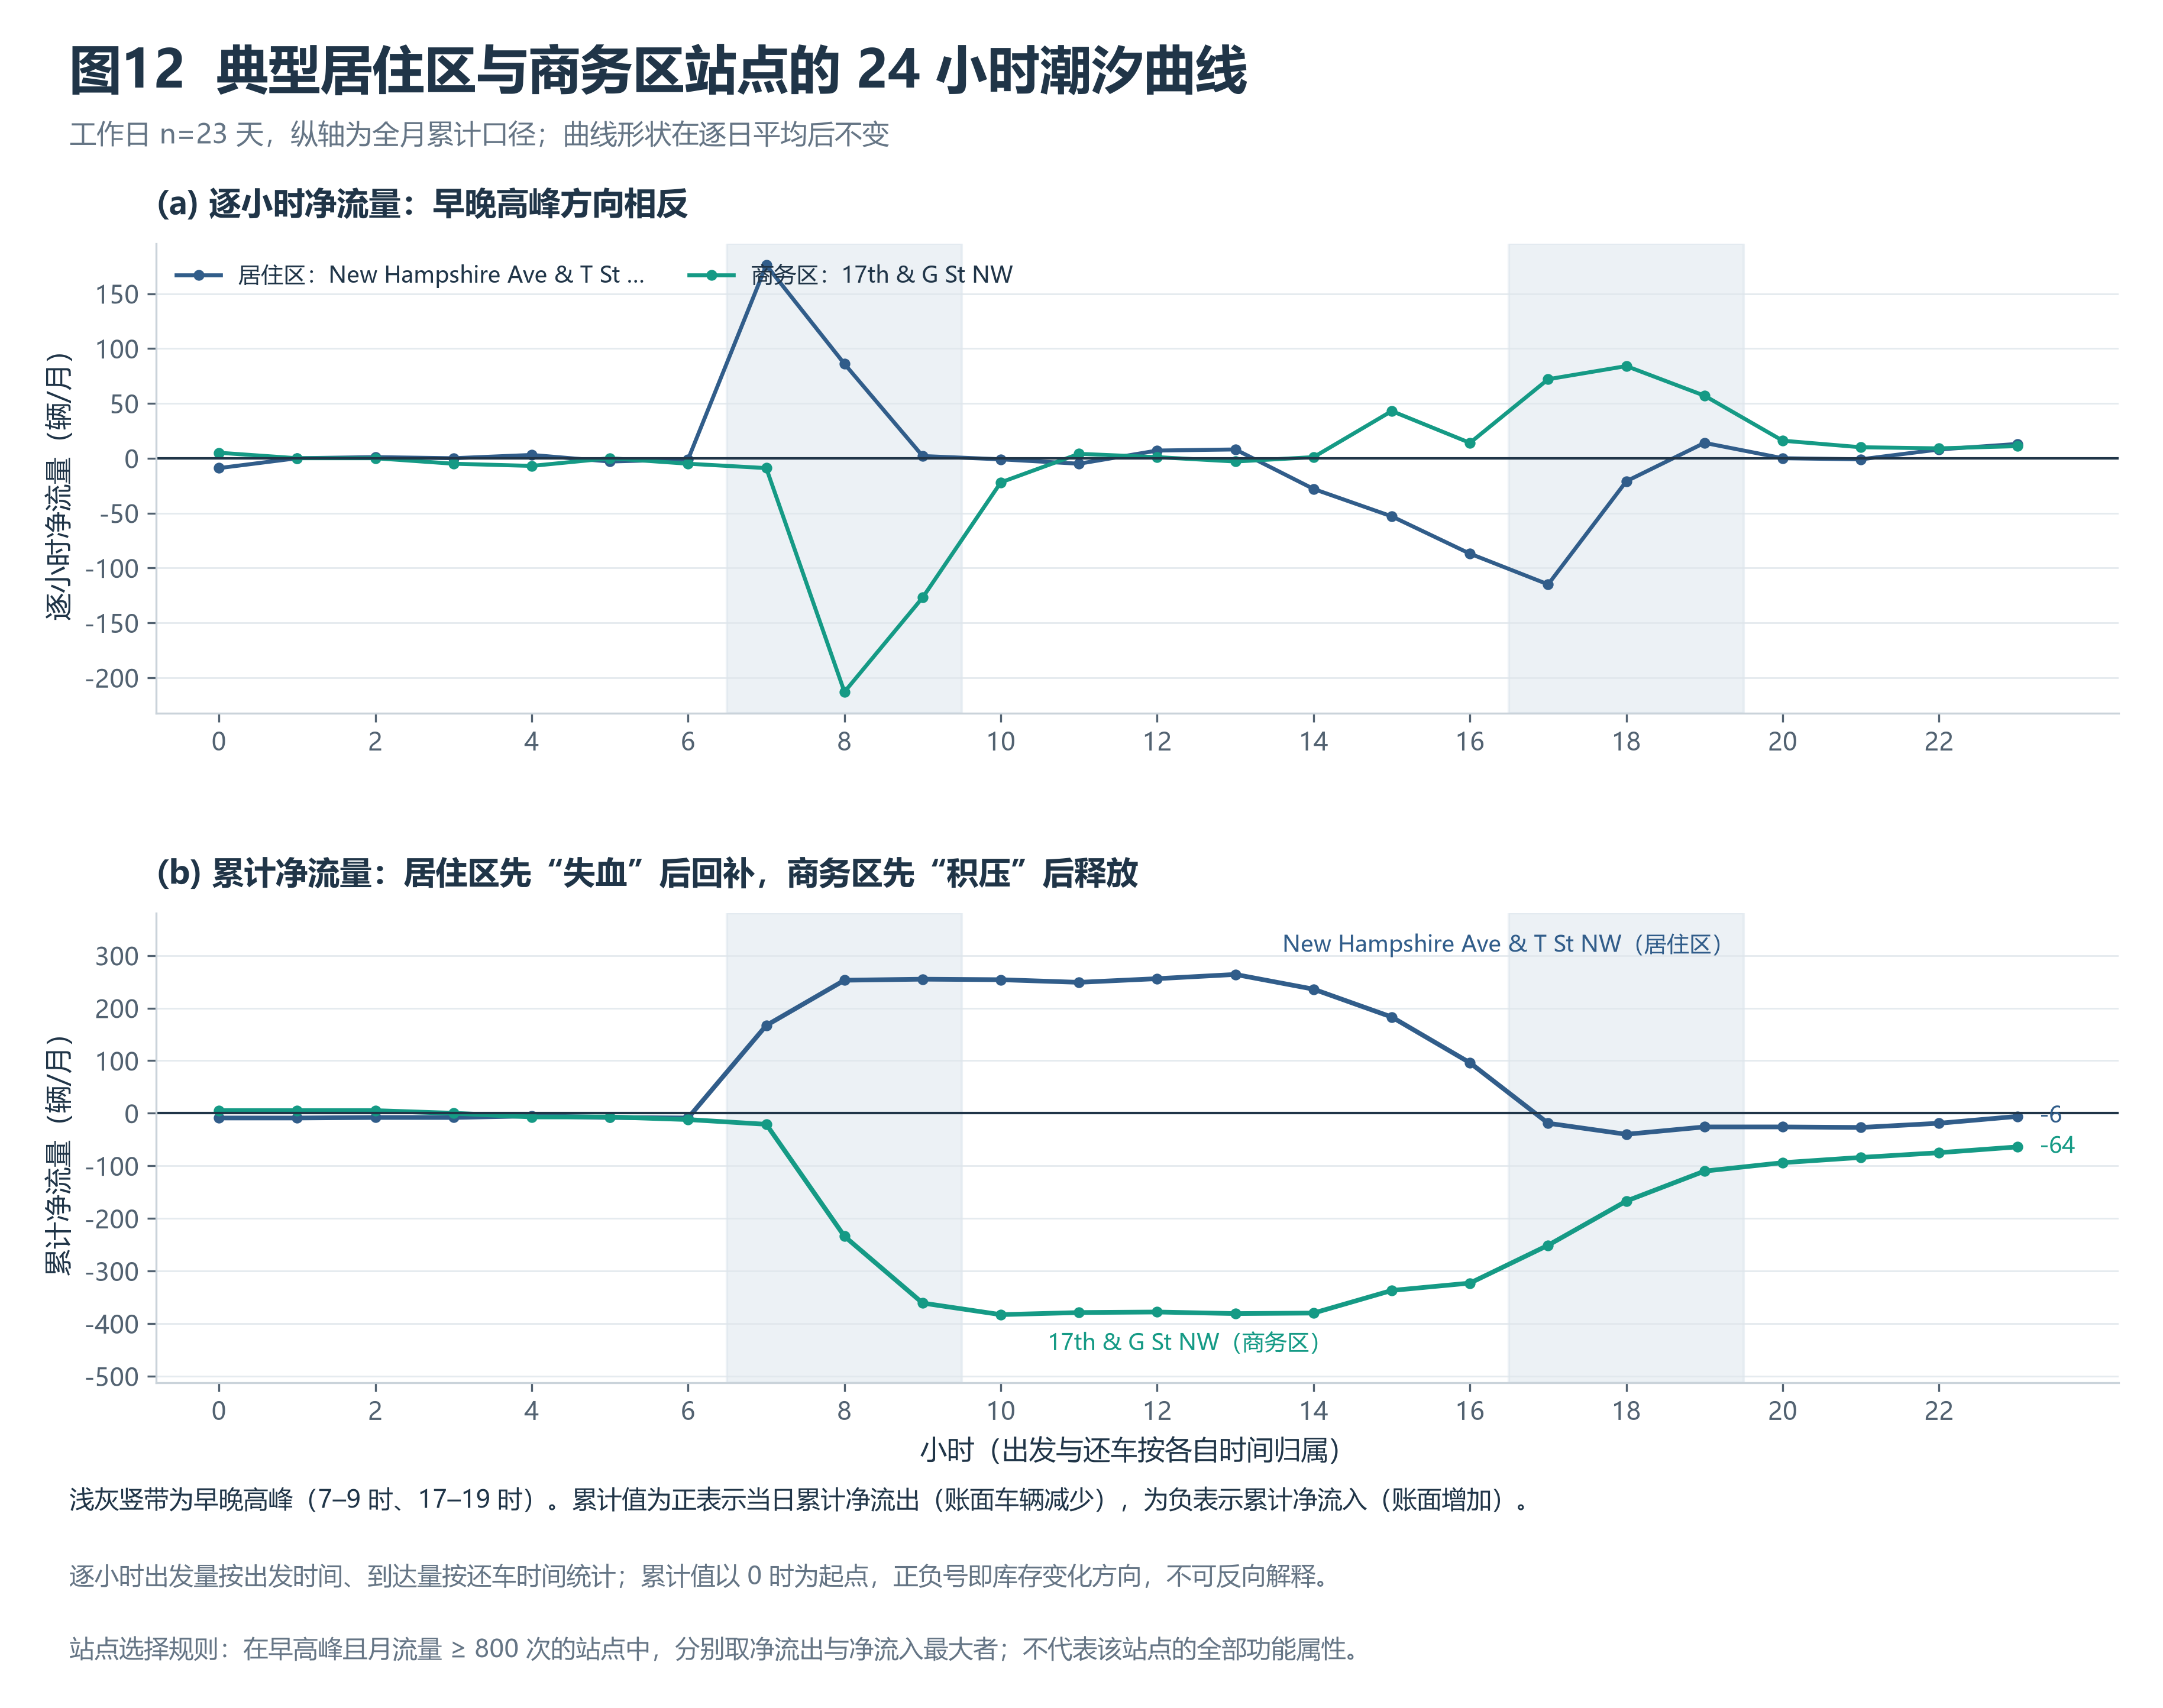

In [11]:
figure = plot_tidal_curves(profiles, days)
fig12 = save_figure(figure, "fig12_tidal_curves.png")
plt.close(figure)
display(DisplayImage(filename=str(fig12), width=1100))

## 9. 调度策略表

匹配规则：在同一高峰内，按净流出量从大到小处理缺车目标站，每次从 6 km 内剩余可供给量最大的邻站取车，直到需求满足或无可供给站点；量纲换算为辆/日（月累计 ÷ 工作日天数）。方案按“最近邻优先”生成，属于可执行的下界估计，尚未考虑车辆容量、人员班次与路网绕行。

In [12]:
plan = build_dispatch_plan(peak, summary, days)
display(plan.head(12)[["period", "target_station", "source_station", "volume_per_day", "distance_km", "priority"]]
        .rename(columns={"period": "时段", "target_station": "补车站点", "source_station": "取车站点",
                         "volume_per_day": "调运量(辆/日)", "distance_km": "距离(km)", "priority": "优先级"}))
am_plan = plan.loc[plan.period.eq("早高峰")]
am_need = am.loc[am.net_flow.gt(0), "net_flow"].sum() / days
display(Markdown(
    f"共 **{len(plan)}** 条线路，合计 **{plan.volume_per_day.sum():.0f}** 辆/日；"
    f"早高峰部分 **{am_plan.volume_per_day.sum():.0f}** 辆/日，覆盖早高峰缺车量 "
    f"**{am_plan.volume_per_day.sum() / am_need:.1%}**（前 30 个最缺车站点全部满足后的比例）。"
    f"平均单程直线距离 **{plan.distance_km.mean():.2f}** km。"
))

,时段,补车站点,取车站点,调运量(辆/日),距离(km),优先级
0,早高峰,15th & W St NW,15th & L St NW,8.0,1.71,高
1,早高峰,17th & Corcoran St NW,18th & M St NW,7.8,0.83,高
2,早高峰,Maryland Ave & E St NE,14th St & New York Ave NW,7.3,0.71,高
3,早高峰,New Hampshire Ave & T St NW,Massachusetts Ave & Dupont Circle NW,7.0,0.80,高
4,早高峰,13th & O St NW/ Logan Circle,15th & K St NW,6.9,0.82,中
5,早高峰,Park Rd & Holmead Pl NW,17th & K St NW / Farragut Square,6.2,3.22,中
6,早高峰,14th St & Rhode Island Ave NW,Vermont Ave & I St NW,6.1,0.85,中
7,早高峰,13th & D St NE,Eastern Market Metro / Pennsylvania Ave & 8th ...,5.7,1.36,高
8,早高峰,Columbia Rd & Georgia Ave NW,13th St & New York Ave NW,5.6,3.12,中
9,早高峰,14th & Belmont St NW,15th St & New York Ave NW,5.4,2.45,中


共 **130** 条线路，合计 **380** 辆/日；早高峰部分 **216** 辆/日，覆盖早高峰缺车量 **36.5%**（前 30 个最缺车站点全部满足后的比例）。平均单程直线距离 **1.45** km。

## 10. 生成图表文件与校验

最后调用 `src/` 的正式入口重跑两条流水线，把图9–图12 的 PNG、自包含 HTML 和配套统计表写回项目目录，并做数据一致性校验。

In [13]:
from src import imbalance_dispatch, spatial_analysis

spatial_stats = spatial_analysis.run()
dispatch_stats = imbalance_dispatch.run()

artifacts = sorted(FIGURE_DIR.glob("fig09*")) + sorted(FIGURE_DIR.glob("fig10*")) \
          + sorted(FIGURE_DIR.glob("fig11*")) + sorted(FIGURE_DIR.glob("fig12*"))
display(pd.DataFrame([{"文件": path.name, "大小(KiB)": round(path.stat().st_size / 1024, 1)}
                      for path in artifacts]))
figure_files = {number: sorted(FIGURE_DIR.glob(f"fig{number:02d}_*")) for number in (9, 10, 11, 12)}

已保存：C:\Deepseek\Pyclass\reports\figures\fig09_top_stations_od.png
已保存：C:\Deepseek\Pyclass\reports\figures\fig09_top_stations_od.html


已保存：C:\Deepseek\Pyclass\reports\figures\fig10_station_heatmap.png
已保存：C:\Deepseek\Pyclass\reports\figures\fig10_station_heatmap.html
站点 760 个；非环线 OD 29,005 个站点对；Top10 走廊占非环线骑行 1.42%。


工作日 23 天；早高峰出发 28,779 次 / 到达 28,281 次，晚高峰出发 37,690 次 / 到达 39,084 次（到达按还车时间统计）。
早高峰：缺车合计 13,628 辆、积车合计 13,130 辆、窗口边界净流量 +498 辆；严重失衡 156 个站点。
晚高峰：缺车合计 7,535 辆、积车合计 8,929 辆、窗口边界净流量 -1,394 辆；严重失衡 44 个站点。
代表站点：居住区=New Hampshire Ave & T St NW；商务区=17th & G St NW


已保存：C:\Deepseek\Pyclass\reports\figures\fig11_peak_divergence.png
已保存：C:\Deepseek\Pyclass\reports\figures\fig11_peak_divergence.html


已保存：C:\Deepseek\Pyclass\reports\figures\fig12_tidal_curves.png
已保存：C:\Deepseek\Pyclass\reports\figures\fig12_tidal_curves.html
调运方案 130 条线路，合计 380 辆/日。


,文件,大小(KiB)
0,fig09_top_stations_od.html,515.4
1,fig09_top_stations_od.png,833.2
2,fig10_station_heatmap.html,522.7
3,fig10_station_heatmap.png,893.1
4,fig11_peak_divergence.html,516.5
5,fig11_peak_divergence.png,863.2
6,fig12_tidal_curves.html,396.9
7,fig12_tidal_curves.png,620.0


In [14]:
checks = {
    "站点有效集 180,914 行": len(station) == 180914,
    "出发量合计 = 到达量合计 = 记录数": int(summary.departures.sum()) == len(station) == int(summary.arrivals.sum()),
    "窗口净流量 = 出发量 − 到达量": bool(
        np.isclose(am.net_flow.sum(), am.departures.sum() - am.arrivals.sum())
        and np.isclose(pm.net_flow.sum(), pm.departures.sum() - pm.arrivals.sum())
    ),
    "到达量按还车时间统计（窗口到达数与逐小时面板一致）": bool(
        int(am.arrivals.sum()) == int(panel.loc[panel.hour.between(7, 9), "arrivals"].sum())
    ),
    "失衡指数位于 [0, 1)": bool((peak.imbalance_index >= 0).all() and (peak.imbalance_index < 1).all()),
    "调运量不超过取车站可供给量": bool((plan.volume_per_day <= plan.source_capacity_per_day + 1e-9).all()),
    "图9–图12 均导出 PNG 与 HTML": all(len(files) >= 2 for files in figure_files.values()),
}
for name, passed in checks.items():
    print(("通过  " if passed else "失败  ") + name)
assert all(checks.values())

display(Markdown(
    f"- 站点 {spatial_stats['stations']} 个，非环线 OD {spatial_stats['corridors']:,} 个站点对；"
    f"Top10 走廊占非环线骑行 {spatial_stats['top10_share']:.2%}。\n"
    f"- 早高峰 {dispatch_stats['am_trips']:,} 次、晚高峰 {dispatch_stats['pm_trips']:,} 次；"
    f"严重失衡站点 {dispatch_stats['am_severe']} / {dispatch_stats['pm_severe']} 个。\n"
    f"- 调运方案 {dispatch_stats['routes']} 条线路，合计 {dispatch_stats['volume_per_day']:.0f} 辆/日。"
))

通过  站点有效集 180,914 行
通过  出发量合计 = 到达量合计 = 记录数
通过  窗口净流量 = 出发量 − 到达量
通过  到达量按还车时间统计（窗口到达数与逐小时面板一致）
通过  失衡指数位于 [0, 1)
通过  调运量不超过取车站可供给量
通过  图9–图12 均导出 PNG 与 HTML


- 站点 760 个，非环线 OD 29,005 个站点对；Top10 走廊占非环线骑行 1.42%。
- 早高峰 28,779 次、晚高峰 37,690 次；严重失衡站点 156 / 44 个。
- 调运方案 130 条线路，合计 380 辆/日。